<a href="https://colab.research.google.com/github/elliemeltzer/econ3916-lab19-random-forests/blob/main/lab_ch19_EM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 19: Tree-Based Models — Random Forests
## ECON 3916: Applied Machine Learning for Economists
### Guided Construction Lab | 40 min Core + 55 min AI + 25 min Extension

---

**Learning Objectives:**
- See a single tree memorise its training rows, and a forest of such trees generalise
- Compare a forest with OLS and Ridge on the same split, and read its out-of-bag score
- Compare impurity (MDI) and permutation importance, and explain why they disagree
- Tune `max_depth` and `max_features` by cross-validation
- Write your own prompt for a feature-importance chart, and check the AI's numbers against the lab's

**Dataset:** California Housing (scikit-learn): 20,640 block groups, 8 features, and the median
house value in units of $100,000. You have used it since Lab 4.

**Prerequisites:** the Part 0 sections of Labs 1-5, and the labs before this one. Lab 16's
pipeline with `StandardScaler` and Lab 15's bias-variance curve are used again here.

**How this lab works:** Parts 1-3 are GUIDED: run each cell as it is, then answer the questions.
The AI-Assisted Expansion is required: as in Lab 16, you write the prompt yourself. The Extension
is optional.

**Plan on about 1 hour 55 minutes** for the required work: setup, Parts 1-3, the AI-Assisted
Expansion, and the README and submission.

**AI in the manual parts:** you may ask Colab to *explain* an error or a line of code (click **Explain error**, or select a line and ask Gemini to explain it). Do not ask it to write or fix code, and turn off AI code completion while you work on those parts. AI-assisted coding is allowed only where this lab says so.

---

> ### What you write, and what you run
>
> **You write:**
> - The answers to the interpretation questions, in text cells: two after Part 1, and one each after Parts 2 and 3.
> - **The AI-Assisted Expansion:** your own prompt, from scratch, asking AI for a function that charts a model's feature importances and gives them back as a table; a revised prompt for round 2 (and round 3 if you need it); the AI's reply to each round, as a share link or the text; a short checking log; and two answers. Your prompts, the AI's replies, the log and the answers are what is graded, not the AI's code.
>
> **You run and read:** everything else. Setup and Parts 1-3 are working code to learn from. Read each cell before you run it, and make sure you can say what each line does. The check cells in the AI section: run them; you need not follow their code. The AI's function is pasted, not typed.
>
> **The Extension** (optional) has one guided cell, then a task with no starter code that you write in a new cell. The **README** is text only: the prompt at the end is for documentation, not code.

## Setup

The first line of the setup cell upgrades scikit-learn to 1.9 or later, because the way trees
are built changed in 1.9: with an older version, the tree and forest numbers in this notebook
differ in the third or fourth decimal. The cell prints your scikit-learn version. If it shows a version below 1.9, use **Runtime → Restart session** and run this cell again.

Every model in this lab is given `random_state=RANDOM_STATE`, so running a cell twice gives the
same numbers.

`fetch_california_housing()` downloads the data the first time (a few seconds) and returns it in
parts: `.data` holds the features, `.target` the house values and `.feature_names` the column
names. `pd.DataFrame(data.data, columns=...)` puts the features in a table with those names.
`train_test_split` keeps 20% of the rows (`test_size=0.2`) as test rows, as in Lab 12.

In [20]:
# GUIDED — run as-is
# Step 1: imports, and California Housing split into training and test rows
!pip install "scikit-learn>=1.9" -q

import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f'scikit-learn {sklearn.__version__} (this lab\'s numbers assume 1.9 or later)')
print(f'Training set: {X_train.shape[0]} observations, {X_train.shape[1]} features')
print(f'Test set: {X_test.shape[0]} observations')
print(f'Features: {list(X.columns)}')

# savefig will not create a folder, and a fresh Colab session has no figures/ folder
Path("figures").mkdir(exist_ok=True)

scikit-learn 1.9.1 (this lab's numbers assume 1.9 or later)
Training set: 16512 observations, 8 features
Test set: 4128 observations
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


**Expected output:** 16512 training rows with 8 features, 4128 test rows, and the eight feature
names from `MedInc` (median income, in $10,000s) to `Longitude`.

## Part 1: Decision Tree vs. Random Forest vs. Ridge (GUIDED — 14 min)

We compare four models on the same rows. The question: does the forest's added complexity give
better predictions than simpler alternatives?

Step 2 fits them, each with `.fit(X, y)`, predictors first:
- a **single tree**, `DecisionTreeRegressor`, with no depth limit: it keeps splitting until it
  cannot;
- **OLS**, `LinearRegression`, as in Lab 12;
- **Ridge**, in a pipeline behind `StandardScaler`, as in Lab 16: the penalty falls evenly across
  the features only when they share one scale;
- a **random forest** of 100 trees, `RandomForestRegressor`. Each tree is grown on a bootstrap
  sample of the training rows, so it never sees about a third of them: its *out-of-bag* rows.
  `oob_score=True` asks the forest to score every training row using only the trees that never
  saw it.

Then it scores each model on the training rows and on the test rows. RMSE, the root of the mean
squared error, is in the target's units, $100,000s. The loop collects one dictionary per model,
and `pd.DataFrame(rows).set_index("Model")` turns the list into a table with one row per model.

In [21]:
# GUIDED — run as-is
# Step 2: four models on the same training rows, scored on both sets
tree = DecisionTreeRegressor(random_state=RANDOM_STATE)      # no depth limit
tree.fit(X_train, y_train)

ols = LinearRegression()
ols.fit(X_train, y_train)

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)

rf = RandomForestRegressor(n_estimators=100, oob_score=True, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

rows = []
for name, model in [('Single Tree', tree), ('OLS', ols),
                    ('Ridge', ridge), ('Random Forest', rf)]:
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    rows.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred),
    })

results_df = pd.DataFrame(rows).set_index('Model')
print(results_df.round(4))

               Train RMSE  Test RMSE  Train R²  Test R²
Model                                                  
Single Tree        0.0000     0.7030    1.0000   0.6228
OLS                0.7197     0.7456    0.6126   0.5758
Ridge              0.7197     0.7456    0.6126   0.5758
Random Forest      0.1882     0.5060    0.9735   0.8046


**Expected output:**

| Model | Train RMSE | Test RMSE | Train R² | Test R² |
|---|---|---|---|---|
| Single Tree | 0.0000 | 0.7093 | 1.0000 | 0.6161 |
| OLS | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Ridge | 0.7197 | 0.7456 | 0.6126 | 0.5758 |
| Random Forest | 0.1882 | 0.5063 | 0.9735 | 0.8044 |

Step 2, continued, looks inside the tree and the forest. `.get_n_leaves()` counts the tree's
final boxes: each leaf is one rectangle of feature space with one prediction, the mean of its
training rows. `rf.max_features` is how many features each split may choose from; `1.0` means
all of them. `.oob_score_` is the out-of-bag R². `results_df.loc[row, column]` reads one cell of
the table. In the prints, `:,` puts commas in the thousands and `:+.6f` shows six decimals with
the sign.

In [22]:
# GUIDED — run as-is
# Step 2, continued: inside the tree and the forest
print(f"single tree: {tree.get_n_leaves():,} leaves for {len(X_train):,} training rows")
print(f"features each split of the forest may choose from: max_features = {rf.max_features}")
print(f"forest out-of-bag R²: {rf.oob_score_:.4f}   "
      f"test R²: {results_df.loc['Random Forest', 'Test R²']:.4f}")

gap = results_df.loc['Ridge', 'Test R²'] - results_df.loc['OLS', 'Test R²']
print(f"Ridge test R² minus OLS test R²: {gap:+.6f}")

single tree: 15,860 leaves for 16,512 training rows
features each split of the forest may choose from: max_features = 1.0
forest out-of-bag R²: 0.8070   test R²: 0.8046
Ridge test R² minus OLS test R²: +0.000028


**Expected output:** 15,870 leaves for 16,512 training rows; `max_features = 1.0`; an
out-of-bag R² of 0.8069 beside a test R² of 0.8044; and Ridge minus OLS of +0.000028.

Three notes on those lines:
- `max_features = 1.0` is the default the lecture asked you to check: `RandomForestRegressor` lets
  every split choose from every feature unless you say otherwise, so Step 2's forest decorrelates
  its trees only through the bootstrap: it is bagging. Part 3 tries the alternatives.
- The out-of-bag R² never touched a test row, yet lands close to the test R²: each training row is
  scored only by the trees that never drew it, so it is a true held-out score. It is not exactly
  the test R² because the rows differ, and each row is scored by only about a third of the trees.
- The penalty gained Ridge essentially nothing here. With 16,512 training rows and only 8
  features, OLS has almost no variance for a penalty to remove; regularization pays when p is
  large relative to n, as in Lab 16 (p = 200, n = 105).

### Interpretation Questions

1. Which model has the largest gap between its train R² and its test R²? Use the leaf count to explain where that gap comes from.
2. The forest's test R² is 0.23 above Ridge's, with the same eight features. What does that say about how the features relate to house values?

1. The single decision tree has the largest train-test gap. Its training R² is 1.0000, while its test R² is 0.6161, a gap of 0.3839. The tree created 15,870 leaves for 16,512 training observations, so many leaves contain only one or a few observations. This lets the tree almost perfectly memorize the training data, but those highly specific splits do not generalize well to new data.

2. The random forest’s test R² is 0.8044, compared with 0.5758 for Ridge, even though both use the same eight predictors. This suggests that house values have important nonlinear relationships, thresholds, and interactions that the linear Ridge model cannot capture. The forest improves predictions by dividing the feature space into many regions rather than requiring each predictor to have one constant linear effect.

## Part 2: Feature Importance — MDI vs. Permutation (GUIDED — 14 min)

Random forests tell us which features matter most for prediction. But remember: **predictive
importance is not causal importance.** Step 3 measures it two ways, for Step 2's forest.

- **MDI** (mean decrease in impurity), `rf.feature_importances_`, comes free with training. Each
  split lowers the squared error inside its box; MDI adds up those drops for each feature, weighted
  by how many training rows reached the split, and scales them to sum to 1. A split near the root
  reaches most of the training rows, so its drop counts for a lot; a split deep in a tree reaches a
  few rows and counts for little, however much the predictions depend on it.
- **Permutation importance**, `permutation_importance(rf, X_test, y_test, n_repeats=10,
  random_state=RANDOM_STATE)`, uses the fitted forest and the test rows. It shuffles one column
  at a time, which breaks that feature's link with the outcome, and records how far the forest's
  test R² falls (R² is the score `permutation_importance` uses for a regressor unless told
  otherwise). It repeats each shuffle 10 times with different orders, seeded, and
  `.importances_mean` is the average fall.

`pd.Series(values, index=X.columns)` labels each number with its feature. The two Series become
the two columns of one table, sorted by permutation importance, largest first
(`ascending=False`).

In [23]:
# GUIDED — run as-is
# Step 3: impurity (MDI) and permutation importance for Step 2's forest
mdi_importance = pd.Series(rf.feature_importances_, index=X.columns)

perm_result = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE
)
perm_importance = pd.Series(perm_result.importances_mean, index=X.columns)

importance_table = pd.DataFrame({'MDI': mdi_importance, 'permutation': perm_importance})
print(importance_table.sort_values('permutation', ascending=False).round(4))

               MDI  permutation
MedInc      0.5250       0.7329
Latitude    0.0890       0.4427
Longitude   0.0885       0.3361
AveOccup    0.1384       0.2031
HouseAge    0.0546       0.0721
AveRooms    0.0442       0.0277
AveBedrms   0.0297       0.0095
Population  0.0307       0.0080


**Expected output:**

| | MDI | permutation |
|---|---|---|
| MedInc | 0.5250 | 0.7307 |
| Latitude | 0.0889 | 0.4465 |
| Longitude | 0.0886 | 0.3376 |
| AveOccup | 0.1384 | 0.2026 |
| HouseAge | 0.0547 | 0.0726 |
| AveRooms | 0.0442 | 0.0272 |
| AveBedrms | 0.0297 | 0.0091 |
| Population | 0.0306 | 0.0080 |

The AI-Assisted Expansion asks you to reproduce the permutation column with a function written
by AI.

Step 3, continued, draws both columns side by side. A horizontal bar chart (`.plot.barh`) draws
the first row at the bottom, so each Series is sorted smallest first to put the longest bar on
top.

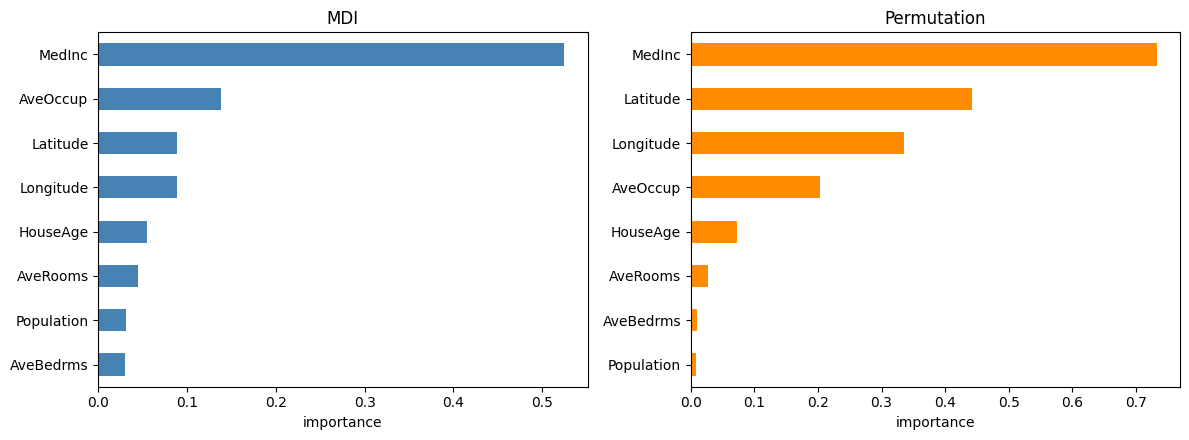

In [24]:
# GUIDED — run as-is
# Step 3, continued: the two measures side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

mdi_importance.sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('MDI')
axes[0].set_xlabel('importance')

perm_importance.sort_values().plot.barh(ax=axes[1], color='darkorange')
axes[1].set_title('Permutation')
axes[1].set_xlabel('importance')

plt.tight_layout()
plt.savefig('figures/ch19_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretation Questions

1. Compare the two columns by rank, 1st to 8th in each, not by the raw numbers: MDI is scaled to sum to 1 and permutation is a fall in test R², so the two are on different scales. Which features does MDI rank higher than permutation does, and what do they have in common? Which does it rank lower, and why?

MDI ranks AveOccup second instead of fourth and Population seventh instead of eighth, so it ranks both higher than permutation importance does. These are continuous features with many possible split points, which can make them more likely to receive impurity-based importance.

MDI ranks Latitude, Longitude, and AveBedrms slightly lower than permutation importance does. Latitude and Longitude are especially important together for representing geographic patterns. Permuting either one disrupts the forest’s test predictions substantially, while MDI may divide their split credit between correlated location variables and other predictors. MedInc, HouseAge, and AveRooms have the same rank under both methods.

## Part 3: Hyperparameter Tuning (GUIDED — 12 min)

Step 4 tunes the forest by cross-validation, with `GridSearchCV`. It fits a fresh forest for every
combination in `param_grid`, on every fold, and keeps the combination with the best average score.
- `max_depth`: 10 levels, or `None`, no limit (as in Step 2).
- `max_features`: how many of the 8 features each split may choose from. `'sqrt'` is √8, rounded
  down to 2; `0.5` is half of them, 4. Step 2 used all 8.
- `cv=3`: three folds, as in Lab 15.
- scikit-learn always keeps the *largest* score, so to minimise the error it scores by minus the
  MSE, `'neg_mean_squared_error'`. `np.sqrt(-score)` turns it back into an RMSE.
- `n_jobs=-1` uses every processor core.

Count the work before you run it: 2 × 2 = 4 combinations × 3 folds = 12 forests, each on about
11,000 rows, plus one more to refit the winner on all the training rows: 13. That takes about a
minute on Colab. A 3 × 3 × 3 grid with 5 folds would be 136 forests, and you would still be
waiting when the lab ended.

After the search, `.best_params_` is the winning combination and `.best_score_` its score.
`.best_estimator_` is a forest with those settings, refitted on all the training rows.
`.cv_results_` holds every combination's settings (`'params'`) and average score
(`'mean_test_score'`), in the same order; `zip` walks through the two lists side by side.
`str()` turns `None` into text, and `:<5` left-aligns it in 5 characters, so the columns line up.

In [25]:
# GUIDED — run as-is (about a minute: 13 forests)
# Step 4: tune max_depth and max_features by 3-fold cross-validation
param_grid = {
    'n_estimators': [100],
    'max_depth': [10, None],
    'max_features': ['sqrt', 0.5],
}
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)

for params, score in zip(grid_search.cv_results_['params'],
                         grid_search.cv_results_['mean_test_score']):
    print(f"max_depth = {str(params['max_depth']):<5} max_features = "
          f"{str(params['max_features']):<5} CV RMSE {np.sqrt(-score):.4f}")

print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV RMSE: {np.sqrt(-grid_search.best_score_):.4f}')

best_rf = grid_search.best_estimator_
best_pred = best_rf.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, best_pred))
test_r2 = r2_score(y_test, best_pred)
print(f'Tuned RF — Test RMSE: {test_rmse:.4f}, Test R²: {test_r2:.4f}')

max_depth = 10    max_features = sqrt  CV RMSE 0.5525
max_depth = 10    max_features = 0.5   CV RMSE 0.5383
max_depth = None  max_features = sqrt  CV RMSE 0.5068
max_depth = None  max_features = 0.5   CV RMSE 0.5034

Best parameters: {'max_depth': None, 'max_features': 0.5, 'n_estimators': 100}
Best CV RMSE: 0.5034
Tuned RF — Test RMSE: 0.4998, Test R²: 0.8094


**Expected output:** CV RMSEs of 0.5522 (depth 10, `'sqrt'`), 0.5382 (depth 10, 0.5), 0.5066
(no limit, `'sqrt'`) and 0.5048 (no limit, 0.5). Then `Best parameters: {'max_depth': None,
'max_features': 0.5, 'n_estimators': 100}`, `Best CV RMSE: 0.5048`, and
`Tuned RF — Test RMSE: 0.4969, Test R²: 0.8116`.

### Interpretation Questions

1. Within the grid, which setting mattered more? Relative to Step 2's forest, which setting did the tuned forest actually change?

Within the tuning grid, max_depth mattered more. Removing the depth limit reduced CV RMSE from 0.5522 to 0.5066 when max_features was sqrt, and from 0.5382 to 0.5048 when max_features was 0.5. Changing max_features produced a smaller improvement.

Compared with the original forest, the tuned model kept max_depth=None and changed only max_features, from all features at each split to half of the features. The tuned model improved test R² from 0.8044 to 0.8116 and reduced test RMSE from 0.5063 to 0.4969.

---

## AI-Assisted Expansion: a feature-importance chart, your prompt, checked by you

Step 3 took two cells to compute permutation importance and chart it. A function that does both
for any fitted model, and hands back the numbers as a table, is code you would reuse in every
project, and quick for AI to write. It also makes every choice your prompt leaves out, and most of
those choices change the numbers. As in Lab 16, no prompt is given: you write it.

**The target.** Given Step 2's forest and the test rows, your function must reproduce Step 3's
permutation column, all eight features, from **MedInc 0.7307** to **Population 0.0080**. Asked for
the top 3, it must give back MedInc, Latitude and Longitude, in that order, with the same numbers.

**What the check calls.** `importance_chart(model, X, y, k)`: an already fitted `model`, a
DataFrame `X`, the outcome `y`, and `k`, the number of features to keep. It draws a horizontal bar
chart of the top `k` and gives back a pandas DataFrame with columns `feature` and `importance`,
largest first. The check runs it on a copy of Step 2's `rf` with `X_test` and `y_test`, at `k = 8`
and `k = 3`, and counts the forests it fits while it runs (Step 3 fitted none). Then it runs it once
more, at `k = 4`, on a model and rows it has not seen: a tree 6 levels deep, fitted on the training
rows with the columns in reverse order, and the first 500 test rows, beside `permutation_importance`
run on that tree directly. A function that uses the notebook's `rf`, `X_test`, `y_test` or feature
names instead of its own arguments fails there.

**What a good prompt states.** Step 3 and the paragraph above hold every answer.
- the function's name, its arguments in order and their types, and what it gives back;
- the model: what it is, and that it arrives already fitted;
- which importance, and every setting that changes its numbers;
- how the top `k` are picked and sorted;
- the chart: its type, its labels, and which bar goes on top;
- what to leave out (example data, a model of its own), and a comment on each line.

**What to do**
1. Write your round 1 prompt in the cell below and send it, exactly as written, to Claude
   ([claude.northeastern.edu](https://claude.northeastern.edu)) or ChatGPT, in a new chat.
2. Put the AI's reply in the reply cell under your prompt: the chat's share link, or, if your chat
   cannot make one, the whole reply copied in as text. The conversation is graded with your prompt.
3. Read the reply before you run anything. Paste only the function into the round 1 code cell, and
   run the check below it.
4. If a line says `NO`, find the choice in the function that caused it, state that choice in a
   round 2 prompt, and put the reply and the new function in the round 2 cells. A third round goes
   in the round 3 cells under them: new cells, so round 2's function and its check stay in your
   notebook as they ran. Stop when every line says `yes` and you can explain each line, or when
   you decide to stop.
5. If everything says `yes` in round 1, use round 2 to state one choice your prompt never asked
   for, and check that it still matches.
6. Fill in the checking log and answer the two questions. Those, your prompts and the AI's replies
   are graded, not the code.

**Reading the check.** For each `k` it prints Step 3's features in order beside the AI's, then one
line per feature: your number, the AI's, `same?`, and the % apart. Same forest, same rows, same
session: a correct function agrees in every printed digit, whether the rows arrive as a DataFrame
or an array and however many processor cores do the work. There is no allowed gap: a `NO` beside
the same printed digits, with a tiny % apart, means the function rounds its numbers. The last block
compares the function with `permutation_importance` on the other tree (its chart appears too). When every line says `yes`,
the check ends with a line that says so. It does not read the chart: compare its bars with the
table yourself. Each check runs the function twice on all 4,128 test rows, so it takes about as
long as Step 3 twice over: up to a minute on Colab.

Keep the function's name and argument order. If the AI also wrote example data or fitted its own
model, leave that out: it can replace the lab's.

In [26]:
# GUIDED — run as-is (you need not follow this code; the cells below use it)
# The check, as a function: the cells below run it once for each round.
# It saves the forest, the test rows and Step 3's numbers now, before anything is pasted.
import copy
try:
    from sklearn.ensemble._forest import BaseForest     # the class every scikit-learn forest builds on
except ImportError:                                     # if a later release moves it
    BaseForest = RandomForestRegressor

# Step 1's split, rebuilt from the data and the seed: a later cell that reuses the names is caught
_d = fetch_california_housing()
step1_split = train_test_split(pd.DataFrame(_d.data, columns=_d.feature_names), _d.target,
                               test_size=0.2, random_state=RANDOM_STATE)

PROBLEMS = {
    "split": "X_train, X_test, y_train or y_test no longer hold Step 1's split: a cell run after "
             "Step 1 gave those names new data. Usually that is the Extension, if it split with Step 1's "
             "names (it needs its own, such as X_test_c), or pasted code that defined them. Use new "
             "names there, then rerun the notebook from the top (Runtime → Run all).",
    "rf": "rf is no longer Step 2's forest: a cell run after Step 2 gave the name another model, or "
          "refitted it. Usually that is the Extension, if it called its classifier rf (it needs its own "
          "name, such as rf_clf), or pasted code that fitted a model. Use new names there, then rerun "
          "the notebook from the top (Runtime → Run all).",
    "step3": "Step 3's table was made with another forest than the rf you have now. Rerun the notebook "
             "from the top (Runtime → Run all).",
}


def lab_data_problem():
    """None if the split, rf and Step 3's table are still Steps 1-3's; otherwise which one changed."""
    X_tr, X_te, y_tr, y_te = step1_split
    # try runs the lines under it; if they raise an error (say a name is gone), except runs instead
    try:
        if not (X_train.equals(X_tr) and X_test.equals(X_te)
                and np.array_equal(y_train, y_tr) and np.array_equal(y_test, y_te)):
            return "split"
    except Exception:
        return "split"
    try:
        # Step 2's settings, and its out-of-bag score recomputed from Step 1's training outcome
        if not (type(rf) is RandomForestRegressor and rf.n_estimators == 100
                and rf.random_state == RANDOM_STATE and rf.max_features == 1.0
                and np.isclose(r2_score(y_tr, rf.oob_prediction_), rf.oob_score_, rtol=1e-12, atol=0)):
            return "rf"
    except Exception:
        return "rf"
    try:
        if not np.allclose(mdi_importance.values, rf.feature_importances_):
            return "step3"
    except Exception:
        return "step3"
    return None


saved_rf, saved_X, saved_y = rf, X_test.copy(), y_test.copy()
saved_perm = perm_importance.sort_values(ascending=False)     # Step 3's column, largest first

# a model and rows the function has not seen: a 6-level tree on the columns in reverse order
other_cols = list(X_test.columns)[::-1]
other_model = DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE)
other_model.fit(step1_split[0][other_cols], step1_split[2])
other_X, other_y = step1_split[1][other_cols].iloc[:500], step1_split[3][:500]
other_perm = pd.Series(permutation_importance(other_model, other_X, other_y, n_repeats=10,
                                              random_state=RANDOM_STATE).importances_mean,
                       index=other_cols).sort_values(ascending=False)


def show_pair(label, mine, ai):
    """One line: your number, the AI's, whether they agree, and how far apart they are."""
    # rtol=1e-9: equal to about 9 significant digits, so only rounding inside the computer passes
    same = "yes" if np.isclose(mine, ai, rtol=1e-9, atol=0) else "NO"
    pct = 100 * (ai - mine) / abs(mine)
    # a gap under 1%: sign and 2 significant digits, so a tiny one prints like +9.6e-06;
    # otherwise a whole number with its sign, like -200
    apart = f"{pct:+.2g}" if abs(pct) < 1 else f"{pct:+.0f}"
    print(f"  {label:<24}{mine:>10.4f}{ai:>10.4f}{same:>7}{apart:>11}%")
    return same == "yes"


def describe(value):
    """What the function gave back, in a few words."""
    if isinstance(value, (pd.Series, np.ndarray, list, tuple)):
        shown = ", ".join(f"{v:.4f}" if isinstance(v, (int, float, np.number)) else type(v).__name__
                          for v in list(value)[:8])
        return f"a {type(value).__name__}: {shown}"
    return f"a {type(value).__name__}"


def as_table(result):
    """The DataFrame the function gave back, with lower-case column names, or None."""
    if isinstance(result, (tuple, list)):          # (table, chart) or (chart, table)
        tables = [r for r in result if isinstance(r, pd.DataFrame)]
        if tables:
            result = tables[0]
    if not isinstance(result, pd.DataFrame):
        return None
    table = result.rename(columns=lambda c: str(c).lower())
    if "feature" not in table.columns and str(table.index.name).lower() == "feature":
        table = table.reset_index().rename(columns=lambda c: str(c).lower())
    return table


def table_or_message(result, names):
    """The table, or None after saying why the check cannot read what the function gave back."""
    table = as_table(result)
    if table is not None and {"feature", "importance"} <= set(table.columns):
        return table
    if table is not None and "importance" in table.columns and set(map(str, table.index)) <= set(names):
        print("importance_chart gave back a DataFrame with a column named importance, but the feature "
              "names are in its index (the row labels), not in a column of their own.")
    else:
        shown = describe(result) if table is None else f"a DataFrame with columns {list(table.columns)}"
        print(f"importance_chart gave back {shown}.")
    print("The check needs a DataFrame with a column named feature and one named importance.")
    return None


def compare(whose, header, ref, table, k):
    """Print ref's top k beside the AI's rows; give back (every line yes?, a NO beside the same digits?)."""
    ai_names = [str(f) for f in table["feature"]]
    mine_names = list(ref.index[:k])
    print(f"  {whose} top {k}, in order : {', '.join(mine_names)}")
    print(f"  the AI's rows, in order : {', '.join(ai_names)}")
    all_yes = ai_names == mine_names
    print(f"  same features, same order? {'yes' if all_yes else 'NO'}")
    print(f"  {'':<24}{header:>10}{'AI':>10}{'same?':>7}{'% apart':>12}")
    same_digits = False
    for name in mine_names:
        if name not in ai_names:
            print(f"  {name:<24}{ref[name]:>10.4f}{'missing':>10}")
            all_yes = False
            continue
        try:
            ai_value = float(table["importance"][table["feature"].astype(str) == name].iloc[0])
        except Exception:
            print(f"  {name:<24}{ref[name]:>10.4f}   not a number")
            all_yes = False
            continue
        if not show_pair(name, ref[name], ai_value):
            all_yes = False
            same_digits = same_digits or f"{ref[name]:.4f}" == f"{ai_value:.4f}"
    if same_digits:
        print("  A NO beside the same printed digits: the numbers differ only after the 4th decimal. The "
              "usual cause is rounding inside the function (round, .round(4), a format string): give back "
              "the full numbers, and round only when you print.")
    return all_yes


def check_importance_chart(fn):
    """Run the AI's importance_chart on Step 2's forest and the test rows, then on another model."""
    problem = lab_data_problem()
    if problem:
        print(PROBLEMS[problem])
        return
    # callable(x) is True when x is a function that can be called
    if not callable(fn):
        print("importance_chart should be a function. Paste the function the AI wrote.")
        return
    real_fit = BaseForest.fit
    every_line_yes = True
    for k in (8, 3):
        fits = []

        def counting_fit(self, *args, **kwargs):
            fits.append(1)
            return real_fit(self, *args, **kwargs)

        BaseForest.fit = counting_fit        # every forest fitted during the call is counted
        try:
            # a copy of the forest and of the rows, so the function cannot change the lab's
            result = fn(copy.deepcopy(saved_rf), saved_X.copy(), saved_y.copy(), k)
        except Exception as err:
            print(f"With k = {k}, the AI's function stopped with an error. "
                  f"{type(err).__name__}: {err}")
            return
        finally:
            BaseForest.fit = real_fit
        table = table_or_message(result, saved_X.columns)
        if table is None:
            return
        print(f"\nk = {k}")
        every_line_yes &= compare("Step 3's", "Step 3", saved_perm, table, k)
        print(f"  {'forests fitted by it':<24}{0:>10}{len(fits):>10}"
              f"{'yes' if not fits else 'NO':>7}")
        every_line_yes &= not fits

    # once more, on a model and rows it has not seen, beside permutation_importance run directly
    k = 4
    print(f"\nAnother model and other rows, k = {k}: a 6-level tree, the columns in reverse order, "
          f"the first {len(other_X)} test rows")
    try:
        result = fn(copy.deepcopy(other_model), other_X.copy(), other_y.copy(), k)
    except Exception as err:
        print(f"  The AI's function stopped with an error. {type(err).__name__}: {err}")
        print("  It ran on Step 2's forest and the test rows, so look for a line that uses the notebook's "
              "rf, X_test, y_test or feature names instead of the function's own model, X and y.")
        return
    table = table_or_message(result, other_cols)
    if table is None:
        return
    every_line_yes &= compare("the direct run's", "direct", other_perm, table, k)
    try:
        ai = dict(zip(table["feature"].astype(str), table["importance"].astype(float)))
        if len(ai) == k and np.allclose(sorted(ai.values()), sorted(saved_perm.values[:k]), rtol=1e-9, atol=0):
            print("  These are Step 3's numbers, not this tree's: the function uses the notebook's rf, "
                  "X_test or y_test, not the model, X and y it is given.")
        elif (len(ai) == k
              and np.allclose(sorted(ai.values()), sorted(other_perm.values[:k]), rtol=1e-9, atol=0)
              and not all(n in other_perm.index and np.isclose(v, other_perm[n], rtol=1e-9, atol=0)
                          for n, v in ai.items())):
            print("  These are this tree's numbers, beside the wrong names: the function takes the names "
                  "from the notebook (data.feature_names, or X_test's columns), not from the X it is given.")
    except Exception:
        pass
    if every_line_yes:
        print("\nEvery line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest "
              "fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.")
    else:
        print("\nIf a line says NO, find out why before you trust the function.")


problem = lab_data_problem()
if problem:
    print(PROBLEMS[problem])


**Your prompt, round 1.** Write it here, then send it exactly as written.

[Prep] Act as a Python data scientist who creates reusable model-evaluation functions using pandas, matplotlib, and scikit-learn.

[Request] Write a function named importance_chart(model, X, y, k). The model is an already-fitted scikit-learn regression model, X is a pandas DataFrame containing the evaluation predictors and their column names, y contains the evaluation outcomes, and k is the number of features to keep. The function must draw a feature-importance chart and return a pandas DataFrame with exactly two columns named feature and importance.

[Iterate] Use pandas, matplotlib, and sklearn.inspection.permutation_importance. Do not fit or refit the model. Do not create example data or another model, and do not use variables from outside the function. Comment every line. Do not round the importance values inside the function.

[Mechanism Check] Calculate permutation importance on the supplied X and y using the already-fitted model. Use the model’s default regression score, n_repeats=10, and random_state=42. Do not specify a different scoring method. Match each importance value to the corresponding name in X.columns. Sort the complete results from largest to smallest importance, keep the first k rows, and reset the returned table’s index.

[Evaluate] Draw a horizontal bar chart containing the top k features. Label the horizontal axis “importance,” label the vertical axis “feature,” and title the chart “Permutation Feature Importance.” Arrange the bars so the feature with the largest importance appears at the top. Return only the unrounded DataFrame, with the rows ordered from largest to smallest importance. Do not return the chart.

**The AI's reply, round 1.** Paste the chat's share link here, or, if your chat cannot make one,
the whole reply copied in as text.

*Your link or the reply here:*

In [27]:
# Paste the importance_chart function from round 1 here, then run the check below.
# Paste only the function: if the AI also wrote example data or fitted a model, leave it out.
def importance_chart(model, X, y, k):
    # Import pandas for constructing the returned table.
    import pandas as pd

    # Import matplotlib for drawing the horizontal bar chart.
    import matplotlib.pyplot as plt

    # Import the permutation-importance function.
    from sklearn.inspection import permutation_importance

    # Calculate permutation importance using the fitted model and supplied evaluation rows.
    result = permutation_importance(
        model,
        X,
        y,
        n_repeats=10,
        random_state=42
    )

    # Match each feature name with its unrounded mean permutation importance.
    importance_table = pd.DataFrame({
        "feature": X.columns,
        "importance": result.importances_mean
    })

    # Sort all features from largest to smallest importance.
    importance_table = importance_table.sort_values(
        "importance",
        ascending=False
    )

    # Keep the top k features and create a new integer index.
    importance_table = importance_table.head(k).reset_index(drop=True)

    # Reverse the plotting order so the largest horizontal bar appears at the top.
    plotting_table = importance_table.sort_values(
        "importance",
        ascending=True
    )

    # Create the figure and choose its size.
    fig, ax = plt.subplots(figsize=(8, 5))

    # Draw the top-k permutation importances as dark-orange horizontal bars.
    ax.barh(
        plotting_table["feature"],
        plotting_table["importance"],
        color="darkorange"
    )

    # Label the horizontal axis.
    ax.set_xlabel("importance")

    # Label the vertical axis.
    ax.set_ylabel("feature")

    # Add the requested chart title.
    ax.set_title("Permutation Feature Importance")

    # Adjust the layout so the labels fit inside the figure.
    plt.tight_layout()

    # Display the completed chart.
    plt.show()

    # Return the unrounded top-k table in largest-to-smallest order.
    return importance_table

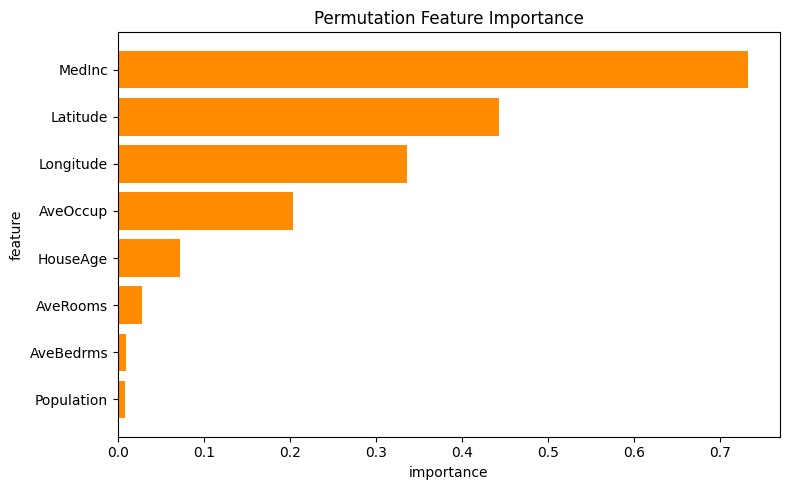


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


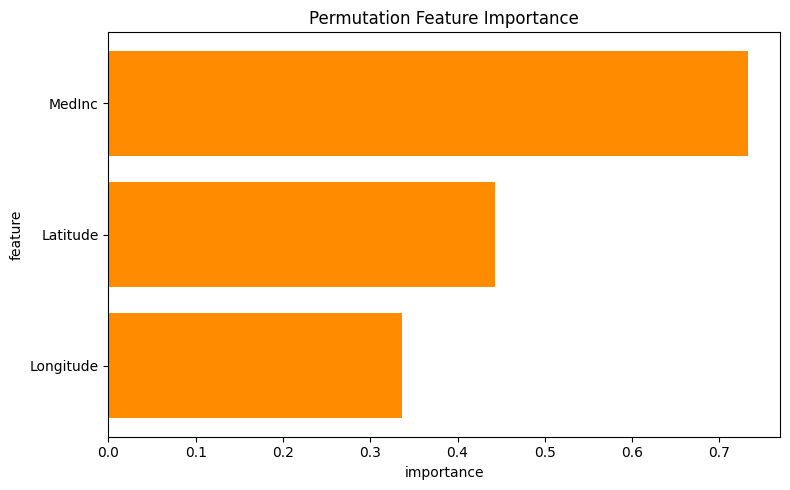


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


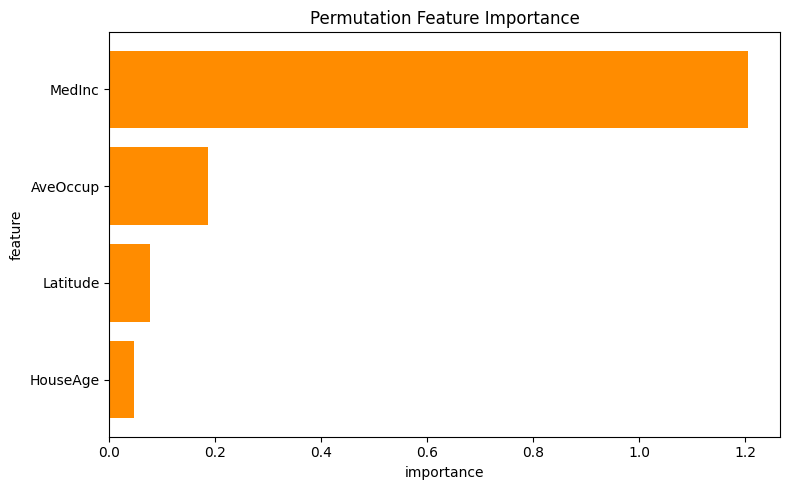

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [28]:
# CHECK — round 1
# To rerun this check, rerun the round 1 paste cell first: it checks whatever was pasted last
# globals() holds every name defined so far in this notebook
if "importance_chart" not in globals():
    print("Paste the AI's importance_chart function in the cell above first, keeping that name, "
          "and run that cell.")
else:
    importance_chart_r1 = importance_chart      # kept, so the round 2 check can tell the two apart
    check_importance_chart(importance_chart_r1)

**Your prompt, round 2.** Keep what worked in round 1, and state what the AI had to choose on its
own.

[Prep] Continue acting as a Python data scientist who creates reusable model-evaluation functions using pandas, matplotlib, and scikit-learn.

[Request] Revise the importance_chart(model, X, y, k) function from your first response. The Round 1 function passed every numerical, ordering, refitting, and generalization check. One choice you made that my first prompt did not state was `figsize=(8, 5)`. I want to keep that figure size explicitly. Keep the darkorange bars and all other successful behavior unchanged.

[Iterate] Continue using pandas, matplotlib, and sklearn.inspection.permutation_importance. Do not fit or refit the supplied model, create example data, use outside variables, or round the importance values. Comment every line.

[Mechanism Check] Continue using the supplied model, X, and y with the model’s default regression score, n_repeats=10, and random_state=42. Match result.importances_mean to X.columns, sort the complete table from largest to smallest, keep the first k rows, and reset the returned table’s index. Reverse the order only for plotting so that the largest bar appears at the top.

[Evaluate] Draw the same horizontal chart with `figsize=(8, 5)` and darkorange bars. Keep the required axis labels and title. Return only the unrounded DataFrame with exactly the columns feature and importance, ordered from largest to smallest. Return the revised function only.

**The AI's reply, round 2.** The share link, or the whole reply as text.

*Your link or the reply here:*

In [29]:
# Paste the importance_chart function from round 2 here, then run the check below.
# Paste only the function: if the AI also wrote example data or fitted a model, leave it out.
def importance_chart(model, X, y, k):
    # Import pandas for constructing the returned table.
    import pandas as pd

    # Import matplotlib for drawing the horizontal bar chart.
    import matplotlib.pyplot as plt

    # Import the permutation-importance function.
    from sklearn.inspection import permutation_importance

    # Calculate permutation importance using the fitted model and evaluation data.
    result = permutation_importance(
        model,
        X,
        y,
        n_repeats=10,
        random_state=42
    )

    # Match every feature name with its unrounded mean permutation importance.
    importance_table = pd.DataFrame({
        "feature": X.columns,
        "importance": result.importances_mean
    })

    # Sort the complete table from largest to smallest importance.
    importance_table = importance_table.sort_values(
        "importance",
        ascending=False
    )

    # Keep the top k features and reset the returned table's index.
    importance_table = importance_table.head(k).reset_index(drop=True)

    # Reverse only the plotting order so the largest bar appears at the top.
    plotting_table = importance_table.sort_values(
        "importance",
        ascending=True
    )

    # Create a figure using the explicitly requested size.
    fig, ax = plt.subplots(figsize=(8, 5))

    # Draw the selected features as dark-orange horizontal bars.
    ax.barh(
        plotting_table["feature"],
        plotting_table["importance"],
        color="darkorange"
    )

    # Label the horizontal axis.
    ax.set_xlabel("importance")

    # Label the vertical axis.
    ax.set_ylabel("feature")

    # Add the requested chart title.
    ax.set_title("Permutation Feature Importance")

    # Adjust the layout so the labels fit inside the figure.
    plt.tight_layout()

    # Display the chart.
    plt.show()

    # Return only the unrounded table in largest-to-smallest order.
    return importance_table

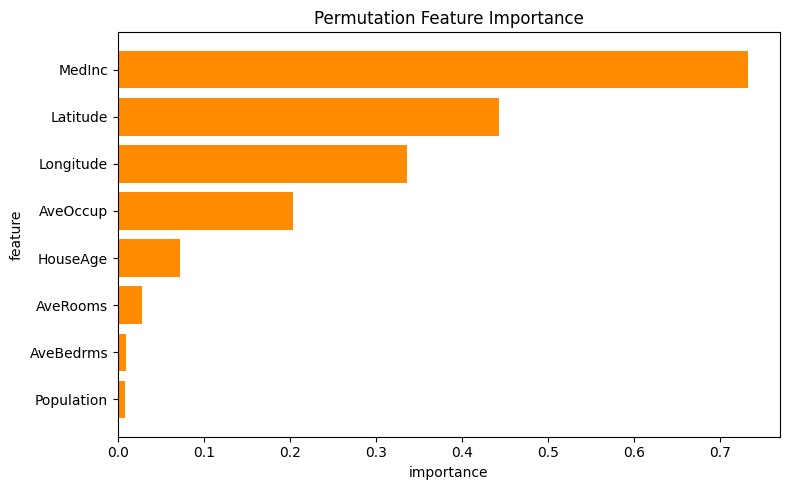


k = 8
  Step 3's top 8, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  the AI's rows, in order : MedInc, Latitude, Longitude, AveOccup, HouseAge, AveRooms, AveBedrms, Population
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  AveOccup                    0.2031    0.2031    yes         +0%
  HouseAge                    0.0721    0.0721    yes         +0%
  AveRooms                    0.0277    0.0277    yes         +0%
  AveBedrms                   0.0095    0.0095    yes         +0%
  Population                  0.0080    0.0080    yes         +0%
  forests fitted by it             0         0    yes


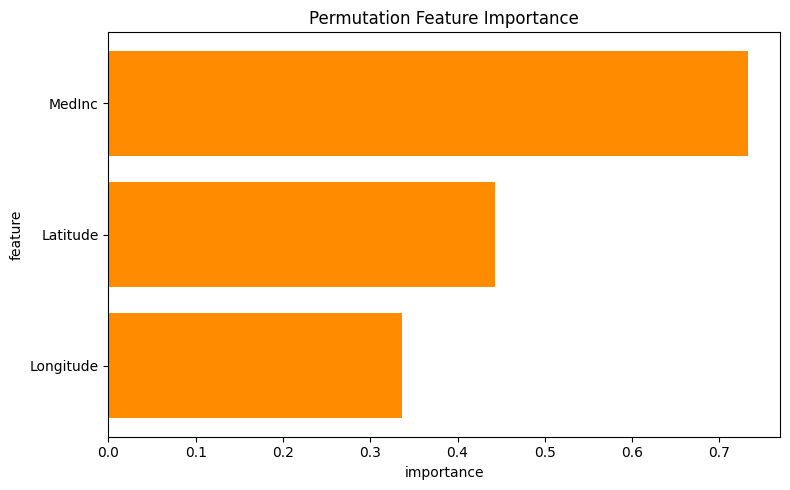


k = 3
  Step 3's top 3, in order : MedInc, Latitude, Longitude
  the AI's rows, in order : MedInc, Latitude, Longitude
  same features, same order? yes
                              Step 3        AI  same?     % apart
  MedInc                      0.7329    0.7329    yes         +0%
  Latitude                    0.4427    0.4427    yes         +0%
  Longitude                   0.3361    0.3361    yes         +0%
  forests fitted by it             0         0    yes

Another model and other rows, k = 4: a 6-level tree, the columns in reverse order, the first 500 test rows


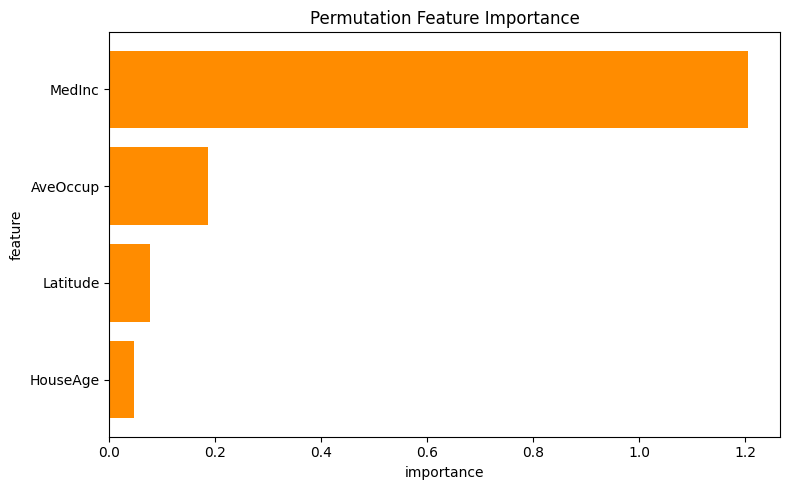

  the direct run's top 4, in order : MedInc, AveOccup, Latitude, HouseAge
  the AI's rows, in order : MedInc, AveOccup, Latitude, HouseAge
  same features, same order? yes
                              direct        AI  same?     % apart
  MedInc                      1.2051    1.2051    yes         +0%
  AveOccup                    0.1866    0.1866    yes         +0%
  Latitude                    0.0774    0.0774    yes         +0%
  HouseAge                    0.0473    0.0473    yes         +0%

Every line says yes: Step 3's numbers in Step 3's order at k = 8 and k = 3, no forest fitted, and the other tree's numbers at k = 4. Now compare the chart with the table yourself.


In [30]:
# CHECK — round 2
# To rerun this check, rerun the round 2 paste cell first: it checks whatever was pasted last
# "is" asks whether two names hold the very same function: if so, nothing new was pasted
if "importance_chart" not in globals() or importance_chart is globals().get("importance_chart_r1"):
    print("Paste the AI's round 2 importance_chart function in the cell above first, "
          "keeping that name, and run that cell.")
else:
    importance_chart_r2 = importance_chart      # kept, so the round 3 check can tell the two apart
    check_importance_chart(importance_chart_r2)

**Round 3, only if you need one.** These are new cells, so round 2's function and its check stay
in your notebook as they ran. Write the round 3 prompt here, with the share link or the reply under it,
then paste the function in the code cell below and run the check under that. If you stopped at round 2,
write "No round 3" here and leave the two code cells as they are.

*Your round 3 prompt, and the link or the reply, here:*

In [31]:
# Round 3 only: paste the importance_chart function from round 3 here, then run the check below.
# Paste only the function: if the AI also wrote example data or fitted a model, leave it out.

In [32]:
# CHECK — round 3 (only if you need one)
# To rerun this check, rerun the round 3 paste cell first: it checks whatever was pasted last
if "importance_chart" not in globals() or any(
        importance_chart is globals().get(name) for name in ("importance_chart_r1", "importance_chart_r2")):
    print("No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise "
          "paste round 3's importance_chart in the cell above, keeping that name, and run that cell.")
else:
    check_importance_chart(importance_chart)

No round 3 function pasted. If you stopped at round 2, leave this cell as it is; otherwise paste round 3's importance_chart in the cell above, keeping that name, and run that cell.


### Checking log

This is graded, with your prompts, the AI's replies and the two answers below. One row per round:
what you checked, how you checked it, and what you found. A row that names the line that differed,
how far apart it was, and the line of the AI's code responsible earns credit; "it worked" does not.
If every line of a round said `yes`, no line differed: name instead the line of the AI's code that
computes the importances, and compare it with Step 3's call yourself, setting by setting (the rows,
the score, the repeats, the seed), saying what you found. The last row is the chart, which the check
does not read: compare its bars with the table of your final round.

| Round | What I checked | How | What I found |
|---|---|---|---|
| 1 | Feature order, numerical importance, refitting, and generalization to another model | I ran the supplied check at k=8 and k=3, then compared it with a direct permutation-importance calculation on a different tree and different rows |Every line said yes. The values were 0% apart, the function fitted zero forests, and it worked on the unseen model and rows.  |
| 2 |  Numerical importance, feature order, refitting, and performance on unseen inputs|I visually compared the chart’s feature order and bar lengths with the final DataFrame  | The chart contained the same top features as the table, and the largest importance appeared at the top as required. |
| 3 (if any) |  |  |  |
| Chart |  |  |  |

### Questions

1. **Critique, in your own words.** Name one choice the AI made that your prompt never stated, quote the line where it makes it, and say whether you would keep it and why. (A choice that caused a `NO` counts. If everything said `yes`, name a line that would give wrong numbers or break on another model or data instead: for example a classifier, whose default score is accuracy, not R²; `X` as a NumPy array; a hard-coded seed.) Then quote the lines of your final function that compute the importances and the lines that sort them and keep the top `k`, and explain in 2-3 sentences, in your own words, what they do and why they give Step 3's numbers.
2. **Judgment: where you stopped.** Which round did you stop at, and why do you, or do you not, trust that function on a model and data the check has never seen? Then: when would you ask AI to write chart code like this, and when would you write it yourself?

*Your answers here:*

1. One choice the AI made that my first prompt did not specify was the figure size. It chose `fig, ax = plt.subplots(figsize=(8, 5))`. I kept this choice because it makes eight horizontal bars and their labels easy to read without making the chart unnecessarily large.

The final function computes the importances with:

`result = permutation_importance(model, X, y, n_repeats=10, random_state=42)`

and matches them to the feature names using:

`importance_table = pd.DataFrame({"feature": X.columns, "importance": result.importances_mean})`

It sorts and keeps the requested features with:

`importance_table = importance_table.sort_values("importance", ascending=False)`

`importance_table = importance_table.head(k).reset_index(drop=True)`

The first lines reproduce Step 3 by using the same evaluation rows, 10 repeats, seed, default regression score, and mean importance values. The final lines place the most important features first, keep only the requested top `k`, and give the returned table a clean integer index.

2. I stopped after Round 2 because every check said yes, the values were 0% apart, the function fitted no new forests, and it worked on a different fitted tree with different rows and reversed columns. I trust it for other fitted regression models with predictor data supplied as a pandas DataFrame, although I would recheck it before using it with a classifier because the model’s default score would then be accuracy rather than R².

I would ask AI to write chart code like this when the task is reusable and the metric, inputs, formatting, and checks can be stated clearly. I would write it myself or review it more closely when the evaluation metric is unusual, the input format differs, or the chart will be used in a production or high-stakes decision.